## Homework: smoothing — answer key

**Station:** Ashalim, 10-minute data from the IMS (`ashalim_2024.csv`), in the Negev desert. **Period:** 10 days in January 2024.

## Import data and basic processing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import savgol_filter

# settings for all the graphs: resolution, and no lines on the top and right of the axes
plt.rcParams.update({'figure.dpi': 110,
                     'axes.spines.top': False,
                     'axes.spines.right': False})

In [2]:
filename = "ashalim_2024.csv"

# the IMS writes '-' where there is no measurement
df = pd.read_csv(filename, na_values=['-'])

# the IMS column that holds the time starts with "Date & Time"
time_column = [c for c in df.columns if c.startswith('Date & Time')][0]

# turn the text into datetimes (the day comes first!) and use them as the index
df['date'] = pd.to_datetime(df[time_column], dayfirst=True)
df = df.set_index('date')

# shorter names for the columns we will use
df = df.rename(columns={'Temperature (°C)': 'temperature',
                        'Rainfall (mm)': 'rain',
                        'Relative humidity (%)': 'humidity',
                        'Global radiation (W/m^2)': 'radiation'})

In [3]:
# 10 consecutive days
start = '2024-01-05'
end = '2024-01-14'
temp = df.loc[start:end, 'temperature']

# no gaps: 10 days with a record every 10 minutes have 1440 records
print("records:", len(temp), " | missing values (NaN):", temp.isna().sum())

records: 1440  | missing values (NaN): 0


## Part 1: how wide should the window be?

### Three window widths

**My prediction:** the 30-minute curve will be almost the data, with only the tiniest noise removed. The 3-hour curve will be smooth, and still show the daily cycle. The 12-hour curve will flatten the daily cycle: lower peaks and higher valleys.

daily cycle in the data:   10.8 °C
daily cycle, window 30min: 10.8 °C
daily cycle, window    3h: 10.5 °C
daily cycle, window   12h: 7.2 °C


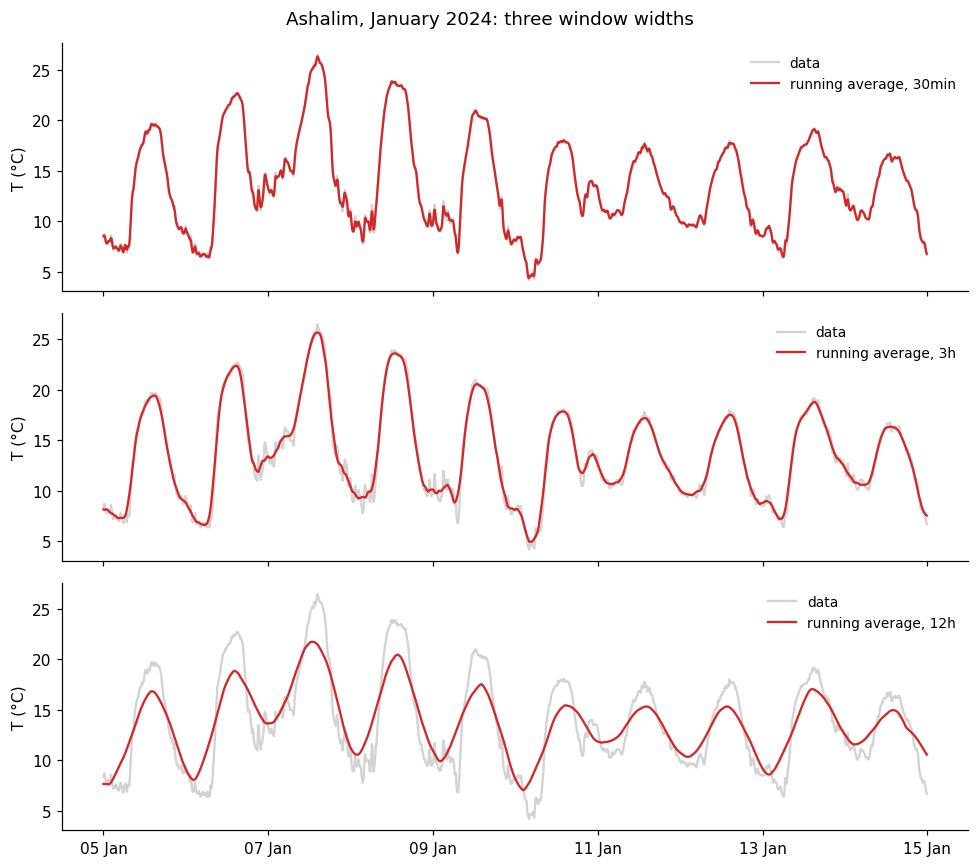

In [4]:
# one panel for each window: the data in gray, the centered running average in red
windows = ['30min', '3h', '12h']

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(9, 8))
for ax, w in zip(axes, windows):
    ax.plot(temp, color='lightgray', label='data')
    ax.plot(temp.rolling(w, center=True).mean(), color='tab:red', label=f'running average, {w}')
    ax.set_ylabel('T (°C)')
    ax.legend(loc='upper right', frameon=False, fontsize=9)
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
fig.suptitle('Ashalim, January 2024: three window widths')
fig.tight_layout()

# how big is the daily cycle in each curve? the mean temperature at each hour of the day, from the lowest to the highest
def daily_cycle(x):
    profile = x.dropna().groupby(x.dropna().index.hour).mean()
    return profile.max() - profile.min()

print(f"daily cycle in the data:   {daily_cycle(temp):.1f} °C")
for w in windows:
    print(f"daily cycle, window {w:>5}: {daily_cycle(temp.rolling(w, center=True).mean()):.1f} °C")

**What I found, and why:** I was right. The 30-minute curve is almost the data, the 3-hour curve is smooth but keeps the daily cycle (10.5 °C, against 10.8 °C in the data), and the 12-hour curve flattens it to 7.2 °C. A small window keeps the fast changes, a large one loses them. For a cold front that lasts one hour I would use 30 minutes, and for the daily cycle 3 hours.

### A strange experiment: 24 hours and 36 hours

**My prediction:** a bigger window smooths more, so I expect the 24-hour curve to be smoother than the 12-hour one, and the 36-hour curve smoother still, with no daily cycle in either.

24 hours: daily cycle 0.3 °C, correlation with the daily cycle of the data: -0.02
36 hours: daily cycle 2.2 °C, correlation with the daily cycle of the data: -0.95


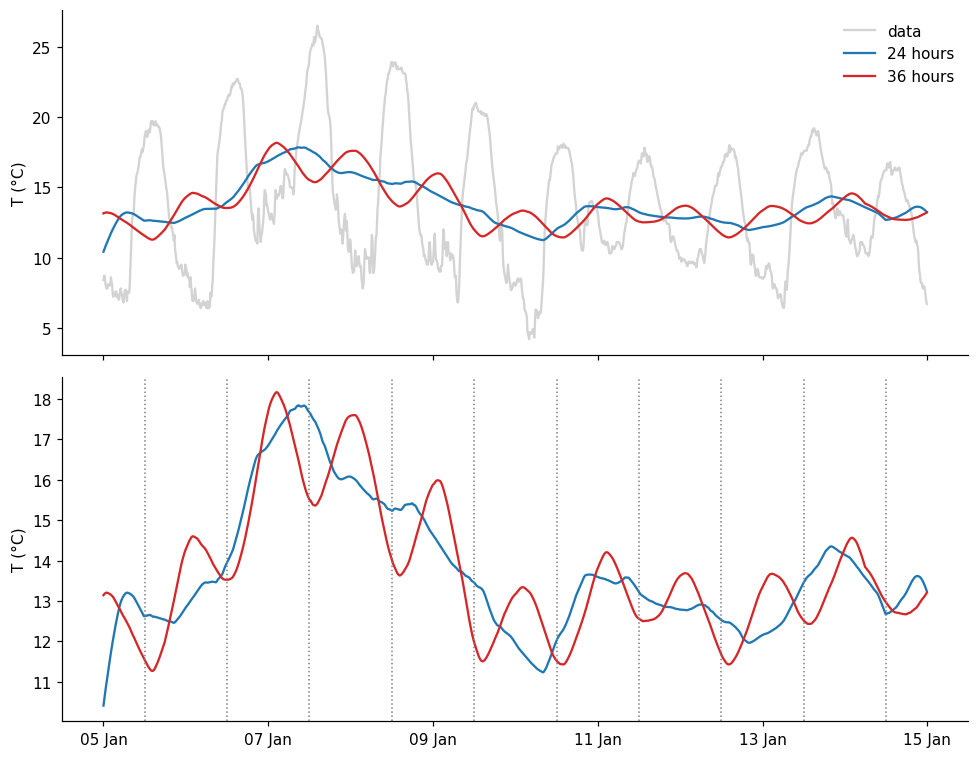

In [5]:
# the same data with a 24-hour window and a 36-hour window
smooth_24 = temp.rolling('24h', center=True).mean()
smooth_36 = temp.rolling('36h', center=True).mean()

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 7))
axes[0].plot(temp, color='lightgray', label='data')
axes[0].plot(smooth_24, color='tab:blue', label='24 hours')
axes[0].plot(smooth_36, color='tab:red', label='36 hours')

# zoom in on the two smoothed curves, with a vertical line at midday of every day, when the data is at its warmest
axes[1].plot(smooth_24, color='tab:blue')
axes[1].plot(smooth_36, color='tab:red')
for day in pd.date_range(start, end):
    axes[1].axvline(day + pd.Timedelta(hours=12), color='gray', ls=':', lw=1)

axes[0].set_ylabel('T (°C)')
axes[1].set_ylabel('T (°C)')
axes[0].legend(loc='upper right', frameon=False)
axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
fig.tight_layout()

# the mean temperature at each hour of the day: how does each curve compare with the data?
hourly = lambda x: x.dropna().groupby(x.dropna().index.hour).mean()
for name, x in [('24 hours', smooth_24), ('36 hours', smooth_36)]:
    corr = np.corrcoef(hourly(x), hourly(temp).loc[hourly(x).index])[0, 1]
    print(f"{name}: daily cycle {daily_cycle(x):.1f} °C, correlation with the daily cycle of the data: {corr:+.2f}")

**What I found, and why:** I was wrong. The 24-hour curve has no daily cycle (0.3 °C), but the 36-hour curve has one again (2.2 °C), and it is **upside down**: its valleys are at midday, when the data is warmest (correlation of -0.95). A 24-hour window contains exactly one full cycle, which cancels out. A 36-hour window contains one and a half cycles, and the extra half cycle comes from the opposite phase. A bigger window does not always smooth more.

## Part 2: spikes and steps

**My prediction:** the spike will become a small bump with the shape of the kernel, 7 points wide and lower than 1. The step will become a ramp, also about 7 points wide, and the triangular and gaussian kernels will make it smoother than the rectangular one.

{'rectangular': np.float64(1.0), 'triangular': np.float64(1.0), 'gaussian': np.float64(1.0)}


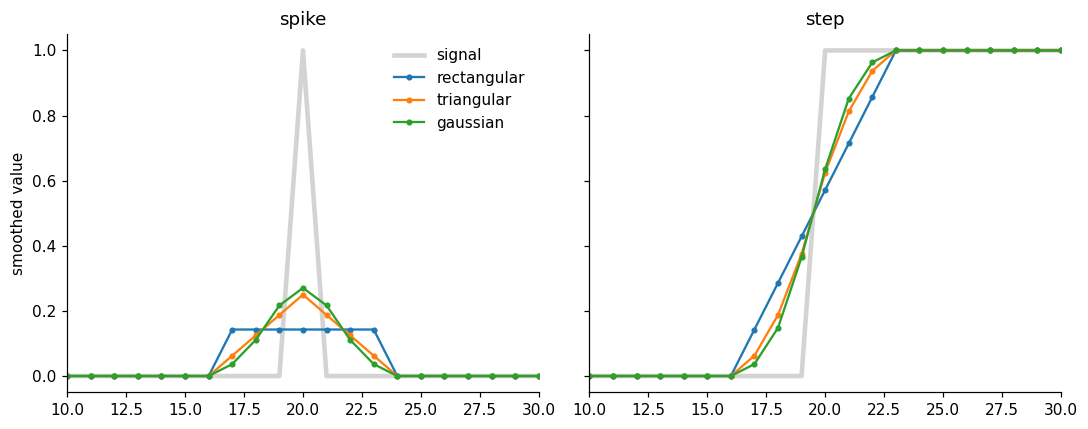

In [6]:
# a spike and a step, 41 points each
x = np.zeros(41)
x[20] = 1
spike = pd.Series(x)
step = pd.Series((np.arange(41) >= 20).astype(float))

# three kernels, all with a window of 7 points
def smooth_all(s):
    return {'rectangular': s.rolling(7, center=True, win_type='boxcar').mean(),
            'triangular': s.rolling(7, center=True, win_type='triang').mean(),
            'gaussian': s.rolling(7, center=True, win_type='gaussian').mean(std=1.5)}

fig, axes = plt.subplots(1, 2, sharey=True, figsize=(10, 4))
for ax, (name, signal) in zip(axes, [('spike', spike), ('step', step)]):
    ax.plot(signal, color='lightgray', lw=3, label='signal')
    for (kernel, result), color in zip(smooth_all(signal).items(), ['tab:blue', 'tab:orange', 'tab:green']):
        ax.plot(result, color=color, marker='o', ms=3, label=kernel)
    ax.set(title=name, xlim=[10, 30])
axes[0].set_ylabel('smoothed value')
axes[0].legend(frameon=False)
fig.tight_layout()

# the sum of the smoothed spike
print({k: round(v.sum(), 3) for k, v in smooth_all(spike).items()})

**What I found, and why:** The smoothed spike is the kernel itself: a flat bump, a triangle and a bell. In all three the sum is exactly 1. The step becomes a ramp about as wide as the window, straight for the rectangular kernel and S-shaped for the other two. A running average cannot describe a sudden change: it makes it gradual, and the larger the window, the more gradual.

## Part 3: three ways to smooth

**My prediction:** the Savitzky-Golay filter will follow the sharp changes best, because it fits a curve and not just an average. The running average will be smooth but will round off the peaks. The resample will lose resolution: only one point every 3 hours.

            data: maximum 26.5 °C
 running average: maximum 25.7 °C
        resample: maximum 25.4 °C
  Savitzky-Golay: maximum 26.0 °C


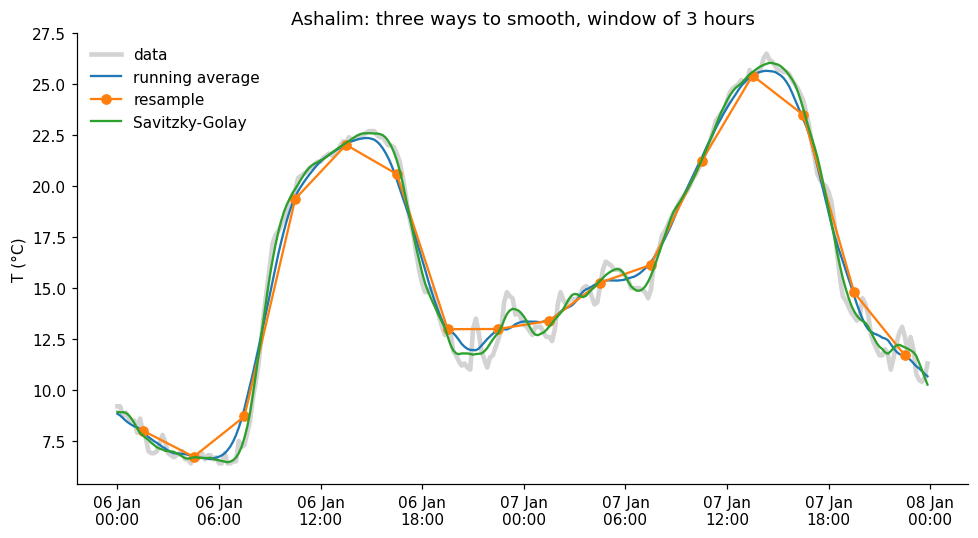

In [7]:
window = 19   # points, about 3 hours

# 1. centered running average
rolling = temp.rolling(window, center=True).mean()

# 2. resample: the mean of every 3 hours (resample puts the point at the beginning of the window, we move it to the middle)
resampled = temp.resample('3h').mean()
resampled.index = resampled.index + pd.Timedelta(hours=1.5)

# 3. Savitzky-Golay, order 2
savgol = pd.Series(savgol_filter(temp.values, window_length=window, polyorder=2), index=temp.index)

# two days, to see the details
zoom = slice('2024-01-06', '2024-01-07')

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(temp.loc[zoom], color='lightgray', lw=3, label='data')
ax.plot(rolling.loc[zoom], color='tab:blue', label='running average')
ax.plot(resampled.loc[zoom], color='tab:orange', marker='o', label='resample')
ax.plot(savgol.loc[zoom], color='tab:green', label='Savitzky-Golay')
ax.set(ylabel='T (°C)', title='Ashalim: three ways to smooth, window of 3 hours')
ax.legend(frameon=False)
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 6)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b\n%H:%M'))
fig.tight_layout()

# the highest temperature of these two days, in the data and in each curve
for name, x in [('data', temp), ('running average', rolling), ('resample', resampled), ('Savitzky-Golay', savgol)]:
    print(f"{name:>16}: maximum {x.loc[zoom].max():.1f} °C")

**What I found, and why:** Savitzky-Golay follows the data best: it keeps the peak (26.0 °C, against 26.5 °C in the data), while the running average rounds it off (25.7 °C) and the resample lowers it even more (25.4 °C). The resample also lost resolution: one point every 3 hours. The price of Savitzky-Golay is that it follows some of the noise (see the small wiggles on 7 January).

### What if... the polynomial order changes?

**My prediction:** a higher order follows the data more closely, but also keeps more of the noise. I expect four different curves, with order 4 the closest to the data.

order 1 = running average: True
order 2 = order 3:         True
order 3 = order 4:         False


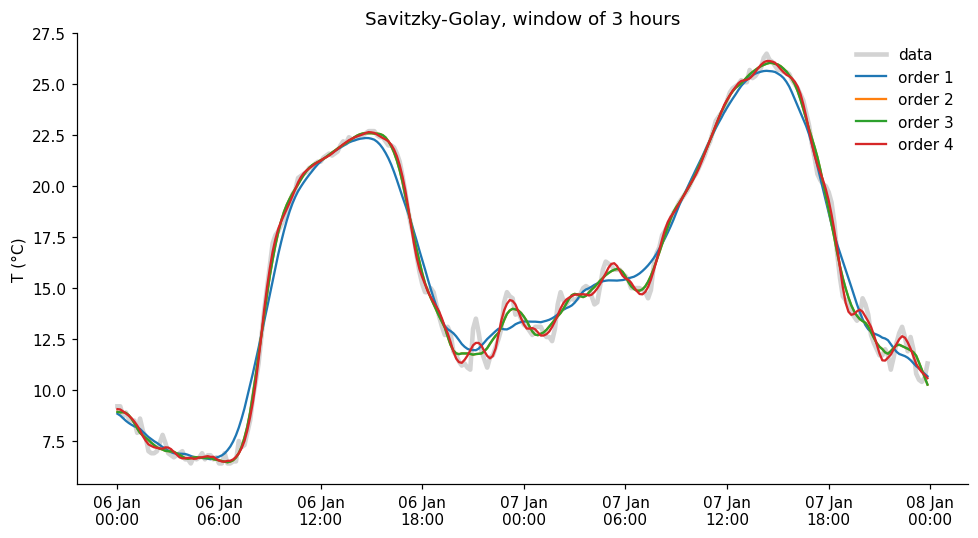

In [8]:
# Savitzky-Golay with four polynomial orders, same window
orders = [1, 2, 3, 4]
savgol_orders = {p: pd.Series(savgol_filter(temp.values, window_length=window, polyorder=p), index=temp.index) for p in orders}

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(temp.loc[zoom], color='lightgray', lw=3, label='data')
for p, color in zip(orders, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']):
    ax.plot(savgol_orders[p].loc[zoom], color=color, label=f'order {p}')
ax.set(ylabel='T (°C)', title='Savitzky-Golay, window of 3 hours')
ax.legend(frameon=False)
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 6)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b\n%H:%M'))
fig.tight_layout()

# which curves are the same? compare only the middle of the data, away from the edges
middle = slice(window, -window)
print("order 1 = running average:", np.allclose(savgol_orders[1].values[middle], rolling.values[middle]))
print("order 2 = order 3:        ", np.allclose(savgol_orders[2].values[middle], savgol_orders[3].values[middle]))
print("order 3 = order 4:        ", np.allclose(savgol_orders[3].values[middle], savgol_orders[4].values[middle]))

**What I found, and why:** I expected four different curves, but there are only three: order 1 is exactly the running average, and orders 2 and 3 are exactly the same (checked with numbers). Only order 4 is different, a bit closer to the data and a bit noisier. I think this is because the window is symmetric: the central value of a fitted straight line is the average, and an extra odd term does not change the central value.

## Part 4: think like in the exam

**1. The spike.**

The result is the kernel itself, centered on the spike: 5 equal values (1/5 each) for the rectangular kernel, and 5 values in the proportion 1, 2, 3, 2, 1 for the triangular one, with the highest in the middle. In both cases the sum is 1: smoothing spreads the value around, but does not create or destroy it, because the weights add up to 1.

**2. The step.**

The step becomes a ramp. With a window of 3 points the values go 0, 1/3, 2/3, 1: the jump is spread over 3 points. With a window of 7 points the ramp is wider (0, 1/7, 2/7, ..., 1), so the transition is slower. The middle of the ramp stays where the step was, because the window is centered.

**3. The three curves A, B and C.**

![](smoothing-question-A.png){width="85%"}

Curve B is almost the data, so it is the 30-minute window. Curve A is the smoothest, with the daily peaks lowered and rounded, so it is the 9-hour window, and C is the 3-hour window. To study the daily cycle I would use C: it removes the noise and keeps the shape, while A already flattens the peaks.

**4. The pink curve.**

![](smoothing-question-B.png){width="85%"}

It is not centered, because the pink curve is delayed with respect to the data: its peak is at about 16:00, and the peak of the data is around 12:00-13:00, and it also rises later. The result of a window that is not centered is assigned to its right end, so the lag is about half the window. A lag of 2-3 hours means a window of about 5-6 hours.

**5. The 7-day average of COVID-19.**

Because the number of cases has a weekly cycle (fewer tests are done on weekends). A window of 7 days contains exactly one full cycle, so the weekly cycle cancels out, just like the 24-hour window cancels the daily cycle. With 5 or 10 days it would not cancel, and would leave a small oscillation, maybe even upside down, as with 36 hours.

**6. Narrow peaks: running average or Savitzky-Golay?**

Savitzky-Golay. A running average flattens the peaks, because it averages the top with its lower neighbors (in our data, a maximum of 25.7 °C against 26.5 °C), while Savitzky-Golay fits a curve in each window and follows the peaks better. The price is that it smooths less, so it keeps more of the noise, and that we have to choose two parameters: the window and the polynomial order.

## AI declaration

This answer key was prepared with Claude Code (Claude), at the instructor's request: it wrote and ran the code and drafted the text. The instructor is responsible for the content.